# Sumativa 1 — IBM HR Employee Attrition

**Integrantes:** Hernán Saavedra, Lenin Salas y Rodrigo Gómez.

## Objetivo
Explorar las características personales y laborales asociadas con la salida
de empleados mediante estadística descriptiva, intervalos de confianza
y pruebas de hipótesis.

Se utiliza el dataset original completo. Los datos son sintéticos;
los resultados no representan una empresa real ni permiten establecer causalidad.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Localizar el archivo desde la raíz o desde la carpeta Sumativa1.
raiz = Path.cwd()

if not (raiz / "datos").is_dir():
    raiz = raiz.parent

ruta_datos = raiz / "datos" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"

if not ruta_datos.is_file():
    raise FileNotFoundError(f"No se encontró el dataset en: {ruta_datos}")

# Conservar el original y trabajar sobre una copia.
original = pd.read_csv(ruta_datos)
df = original.copy(deep=True)

sns.set_theme(style="whitegrid")

print(f"Dataset: {df.shape[0]} registros y {df.shape[1]} columnas")
print(f"Python: {sys.version.split()[0]}")
print(f"pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"SciPy: {scipy.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"seaborn: {sns.__version__}")

display(df.head())

Dataset: 1470 registros y 35 columnas
Python: 3.11.9
pandas: 3.0.6
NumPy: 2.4.6
SciPy: 1.17.1
Matplotlib: 3.11.2
seaborn: 0.13.2


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 1. Revisión de calidad de los datos

Se revisan tipos de almacenamiento, valores faltantes, filas duplicadas,
columnas constantes y unicidad del identificador. También se comprueba
la presencia de espacios adicionales en las variables de texto.

In [2]:
# Resumen de calidad por variable.
calidad = pd.DataFrame({
    "Tipo en pandas": df.dtypes.astype(str),
    "Faltantes": df.isna().sum(),
    "Valores únicos": df.nunique(dropna=False)
})
calidad.index.name = "Variable"

display(calidad)

# Comprobaciones generales.
constantes = df.columns[df.nunique(dropna=False).eq(1)].tolist()
duplicados = int(df.duplicated().sum())
id_unico = df["EmployeeNumber"].is_unique

print("Total de valores faltantes:", int(df.isna().sum().sum()))
print("Filas duplicadas:", duplicados)
print("Columnas constantes:", constantes)
print("EmployeeNumber es único:", id_unico)

# Detectar espacios al inicio o al final de los textos.
columnas_texto = df.select_dtypes(include=["object", "string"]).columns

espacios = pd.Series({
    columna: int(
        df[columna].dropna().ne(df[columna].dropna().str.strip()).sum()
    )
    for columna in columnas_texto
}, name="Registros con espacios adicionales")

display(espacios.to_frame())

# Revisar categorías y sus frecuencias.
for columna in columnas_texto:
    print(f"\n{columna}")
    display(df[columna].value_counts(dropna=False).to_frame("Frecuencia"))

,Tipo en pandas,Faltantes,Valores únicos
Variable,,,
Age,int64,0,43
Attrition,str,0,2
BusinessTravel,str,0,3
DailyRate,int64,0,886
Department,str,0,3
DistanceFromHome,int64,0,29
Education,int64,0,5
EducationField,str,0,6
EmployeeCount,int64,0,1


Total de valores faltantes: 0
Filas duplicadas: 0
Columnas constantes: ['EmployeeCount', 'Over18', 'StandardHours']
EmployeeNumber es único: True


,Registros con espacios adicionales
Attrition,0
BusinessTravel,0
Department,0
EducationField,0
Gender,0
JobRole,0
MaritalStatus,0
Over18,0
OverTime,0



Attrition


,Frecuencia
Attrition,
No,1233
Yes,237


...

,Frecuencia
MaritalStatus,
Married,673
Single,470
Divorced,327



Over18


,Frecuencia
Over18,
Y,1470



OverTime


,Frecuencia
OverTime,
No,1054
Yes,416


### Validación de consistencia

Se comprueba que las variables cuantitativas seleccionadas no tengan
valores negativos y que las duraciones laborales mantengan relaciones
coherentes. También se revisan los códigos de las escalas ordinales.

Estas comprobaciones detectan posibles inconsistencias internas,
pero no garantizan que todos los registros sean correctos.

In [15]:
validaciones = {
    "Edad no positiva": df["Age"].le(0),
    "Ingreso mensual no positivo": df["MonthlyIncome"].le(0),
    "Distancia negativa": df["DistanceFromHome"].lt(0),
    "Experiencia total negativa": df["TotalWorkingYears"].lt(0),
    "Antigüedad negativa": df["YearsAtCompany"].lt(0),
    "Antigüedad mayor que experiencia total":
        df["YearsAtCompany"].gt(df["TotalWorkingYears"]),
    "Años en cargo mayores que antigüedad":
        df["YearsInCurrentRole"].gt(df["YearsAtCompany"]),
    "Años con jefe mayores que antigüedad":
        df["YearsWithCurrManager"].gt(df["YearsAtCompany"]),
    "Años desde promoción mayores que antigüedad":
        df["YearsSinceLastPromotion"].gt(df["YearsAtCompany"])
}

rangos_ordinales = {
    "Education": range(1, 6),
    "EnvironmentSatisfaction": range(1, 5),
    "JobInvolvement": range(1, 5),
    "JobLevel": range(1, 6),
    "JobSatisfaction": range(1, 5),
    "PerformanceRating": range(1, 5),
    "RelationshipSatisfaction": range(1, 5),
    "StockOptionLevel": range(0, 4),
    "WorkLifeBalance": range(1, 5)
}

for variable, valores_validos in rangos_ordinales.items():
    validaciones[f"{variable}: código fuera de rango"] = (
        ~df[variable].isin(valores_validos)
    )

reporte_consistencia = pd.DataFrame({
    "Comprobación": list(validaciones.keys()),
    "Casos detectados": [
        int(condicion.sum()) for condicion in validaciones.values()
    ]
})

display(reporte_consistencia)

# Mostrar los registros que requieren revisión, si existen.
filas_revisar = pd.DataFrame(validaciones).any(axis=1)

print("Registros que requieren revisión:", int(filas_revisar.sum()))

if filas_revisar.any():
    display(df.loc[filas_revisar])

,Comprobación,Casos detectados
0,Edad no positiva,0
1,Ingreso mensual no positivo,0
2,Distancia negativa,0
3,Experiencia total negativa,0
4,Antigüedad negativa,0
5,Antigüedad mayor que experiencia total,0
6,Años en cargo mayores que antigüedad,0
7,Años con jefe mayores que antigüedad,0
8,Años desde promoción mayores que antigüedad,0
9,Education: código fuera de rango,0


Registros que requieren revisión: 0


### Resultado de la revisión de calidad

El dataset contiene 1.470 registros y 35 columnas, sin valores faltantes
ni filas duplicadas. EmployeeNumber identifica de forma única cada registro.

Las comprobaciones aplicadas no detectaron valores fuera de los rangos
definidos ni inconsistencias en las relaciones entre duraciones laborales.
Por ello, no se realizaron correcciones ni se eliminaron registros.

Para el análisis se excluyeron las tres columnas constantes
(EmployeeCount, Over18 y StandardHours) y el identificador EmployeeNumber.
La base resultante conserva 1.470 registros y 31 variables.

Estos controles verifican aspectos específicos de consistencia interna;
no garantizan la ausencia de otros problemas de calidad.

## 2. Clasificación de variables y selección para el análisis

Se distingue el tipo estadístico de cada variable de su almacenamiento
en pandas. Las escalas de satisfacción, educación y nivel laboral se
consideran ordinales.

Se excluyen del análisis las columnas constantes y EmployeeNumber,
porque identifica registros y no representa una medida del empleado.
El dataset original se conserva intacto.

In [3]:
nominales = [
    "Attrition", "Department", "EducationField",
    "Gender", "JobRole", "MaritalStatus", "OverTime"
]

ordinales = [
    "BusinessTravel", "Education", "EnvironmentSatisfaction",
    "JobInvolvement", "JobLevel", "JobSatisfaction",
    "PerformanceRating", "RelationshipSatisfaction",
    "StockOptionLevel", "WorkLifeBalance"
]

importes = ["DailyRate", "HourlyRate", "MonthlyIncome", "MonthlyRate"]

medidas_enteras = ["DistanceFromHome", "PercentSalaryHike"]

def clasificar_variable(columna):
    if columna == "EmployeeNumber":
        return "Identificador"
    if columna in constantes:
        return "Constante"
    if columna in nominales:
        return "Cualitativa nominal"
    if columna in ordinales:
        return "Cualitativa ordinal"
    if columna in importes:
        return "Cuantitativa tratada como continua"
    if columna in medidas_enteras:
        return "Cuantitativa registrada en enteros"
    return "Cuantitativa discreta: conteo o años enteros"

diccionario = pd.DataFrame({
    "Variable": df.columns,
    "Tipo estadístico": [
        clasificar_variable(columna) for columna in df.columns
    ]
})

display(diccionario)

# Crear la base de análisis sin modificar el original.
excluidas = constantes + ["EmployeeNumber"]
analisis = df.drop(columns=excluidas).copy()

print("Columnas excluidas:", excluidas)
print("Dimensiones de la base de análisis:", analisis.shape)

,Variable,Tipo estadístico
0,Age,Cuantitativa discreta: conteo o años enteros
1,Attrition,Cualitativa nominal
2,BusinessTravel,Cualitativa ordinal
3,DailyRate,Cuantitativa tratada como continua
4,Department,Cualitativa nominal
5,DistanceFromHome,Cuantitativa registrada en enteros
6,Education,Cualitativa ordinal
7,EducationField,Cualitativa nominal
8,EmployeeCount,Constante
9,EmployeeNumber,Identificador


Columnas excluidas: ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
Dimensiones de la base de análisis: (1470, 31)


## 3. Estadística descriptiva de variables cuantitativas

Se resumen edad, ingreso mensual, distancia al trabajo, antigüedad
y experiencia laboral total mediante medidas de centro, dispersión y forma.

La curtosis se expresa como exceso de curtosis: una distribución normal
tiene valor 0. Los valores positivos indican mayor peso en las colas
respecto de la distribución normal.

In [4]:
variables_numericas = [
    "Age",
    "MonthlyIncome",
    "DistanceFromHome",
    "YearsAtCompany",
    "TotalWorkingYears"
]

datos_numericos = analisis[variables_numericas]

descriptivos = datos_numericos.describe().T.rename(columns={
    "count": "n",
    "mean": "Media",
    "std": "Desviación estándar",
    "min": "Mínimo",
    "25%": "Q1",
    "50%": "Mediana",
    "75%": "Q3",
    "max": "Máximo"
})

descriptivos["RIC"] = descriptivos["Q3"] - descriptivos["Q1"]
descriptivos["Asimetría"] = datos_numericos.skew()
descriptivos["Exceso de curtosis"] = datos_numericos.kurt()

# Mostrar coma decimal sin modificar los valores utilizados en los cálculos.
display(
    descriptivos.style
    .format(precision=2, decimal=",", thousands=".")
    .format({"n": "{:.0f}"})
)

,n,Media,Desviación estándar,Mínimo,Q1,Mediana,Q3,Máximo,RIC,Asimetría,Exceso de curtosis
Age,1470,36.923810,9.135373,18.000000,30.000000,36.000000,43.000000,60.000000,13.000000,0.413286,-0.404145
MonthlyIncome,1470,6502.931293,4707.956783,1009.000000,2911.000000,4919.000000,8379.000000,19999.000000,5468.000000,1.369817,1.005233
DistanceFromHome,1470,9.192517,8.106864,1.000000,2.000000,7.000000,14.000000,29.000000,12.000000,0.958118,-0.224833
YearsAtCompany,1470,7.008163,6.126525,0.000000,3.000000,5.000000,9.000000,40.000000,6.000000,1.764529,3.935509
TotalWorkingYears,1470,11.279592,7.780782,0.000000,6.000000,10.000000,15.000000,40.000000,9.000000,1.117172,0.918270


In [7]:
    # Copia para presentación; los datos numéricos originales se conservan.
tabla_presentacion = descriptivos.copy()

for columna in tabla_presentacion.columns:
    if columna == "n":
        tabla_presentacion[columna] = tabla_presentacion[columna].map(
            lambda valor: f"{valor:.0f}"
        )
    else:
        tabla_presentacion[columna] = tabla_presentacion[columna].map(
            lambda valor: f"{valor:.2f}".replace(".", ",")
        )

display(tabla_presentacion)

,n,Media,Desviación estándar,Mínimo,Q1,Mediana,Q3,Máximo,RIC,Asimetría,Exceso de curtosis
Age,1470,"36,92","9,14","18,00","30,00","36,00","43,00","60,00","13,00","0,41","-0,40"
MonthlyIncome,1470,"6502,93","4707,96","1009,00","2911,00","4919,00","8379,00","19999,00","5468,00","1,37","1,01"
DistanceFromHome,1470,"9,19","8,11","1,00","2,00","7,00","14,00","29,00","12,00","0,96","-0,22"
YearsAtCompany,1470,"7,01","6,13","0,00","3,00","5,00","9,00","40,00","6,00","1,76","3,94"
TotalWorkingYears,1470,"11,28","7,78","0,00","6,00","10,00","15,00","40,00","9,00","1,12","0,92"


## 4. Frecuencias de variables categóricas

Se calculan frecuencias absolutas y porcentajes para la salida de empleados,
las horas extra, el departamento y la satisfacción laboral.

In [8]:
variables_categoricas = [
    "Attrition",
    "OverTime",
    "Department",
    "JobSatisfaction"
]

frecuencias = {}

for variable in variables_categoricas:
    conteos = analisis[variable].value_counts().sort_index()

    tabla = pd.DataFrame({
        "Frecuencia": conteos,
        "Porcentaje": conteos / len(analisis) * 100
    })

    frecuencias[variable] = tabla

    # Formatear únicamente la copia que se muestra.
    presentacion = tabla.copy()
    presentacion["Porcentaje"] = presentacion["Porcentaje"].map(
        lambda valor: f"{valor:.2f}".replace(".", ",")
    )

    print(f"\n{variable}")
    display(presentacion)


Attrition


,Frecuencia,Porcentaje
Attrition,,
No,1233,"83,88"
Yes,237,"16,12"



OverTime


,Frecuencia,Porcentaje
OverTime,,
No,1054,"71,70"
Yes,416,"28,30"



Department


,Frecuencia,Porcentaje
Department,,
Human Resources,63,"4,29"
Research & Development,961,"65,37"
Sales,446,"30,34"



JobSatisfaction


,Frecuencia,Porcentaje
JobSatisfaction,,
1,289,"19,66"
2,280,"19,05"
3,442,"30,07"
4,459,"31,22"


## 5. Distribución de variables categóricas

Los gráficos muestran el porcentaje de registros en cada categoría.
Estos porcentajes describen la composición del dataset; no corresponden
a porcentajes de salida dentro de cada grupo.

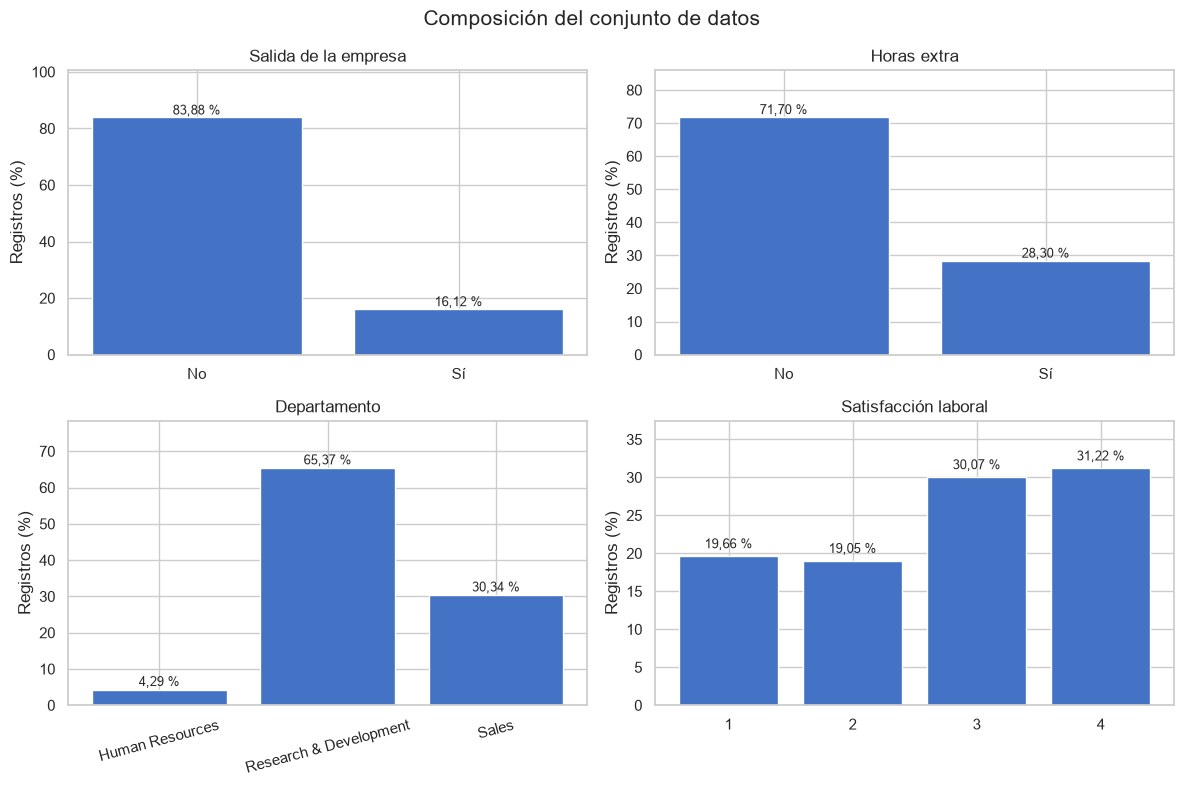

In [9]:
# Carpeta para las figuras de la Sumativa 1.
carpeta_figuras = raiz / "Sumativa1" / "figuras"
carpeta_figuras.mkdir(parents=True, exist_ok=True)

titulos = {
    "Attrition": "Salida de la empresa",
    "OverTime": "Horas extra",
    "Department": "Departamento",
    "JobSatisfaction": "Satisfacción laboral"
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, variable in zip(axes.flat, variables_categoricas):
    tabla = frecuencias[variable]

    etiquetas = [str(categoria) for categoria in tabla.index]

    if variable in ["Attrition", "OverTime"]:
        etiquetas = [
            "Sí" if categoria == "Yes" else "No"
            for categoria in tabla.index
        ]

    barras = ax.bar(
        etiquetas,
        tabla["Porcentaje"],
        color="#4472C4"
    )

    ax.set_title(titulos[variable])
    ax.set_ylabel("Registros (%)")
    ax.set_ylim(0, tabla["Porcentaje"].max() * 1.20)

    for barra, porcentaje in zip(barras, tabla["Porcentaje"]):
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height() + 1,
            f"{porcentaje:.2f} %".replace(".", ","),
            ha="center",
            fontsize=9
        )

    if variable == "Department":
        ax.tick_params(axis="x", labelrotation=15)

fig.suptitle("Composición del conjunto de datos", fontsize=15)
fig.tight_layout()

fig.savefig(
    carpeta_figuras / "figura_1_frecuencias.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Distribución de variables cuantitativas

Se representan edad, ingreso mensual y antigüedad mediante histogramas
y diagramas de caja. Los puntos fuera de los límites del diagrama de caja
son valores potencialmente atípicos; no se eliminan automáticamente,
porque no implican por sí solos errores de registro.

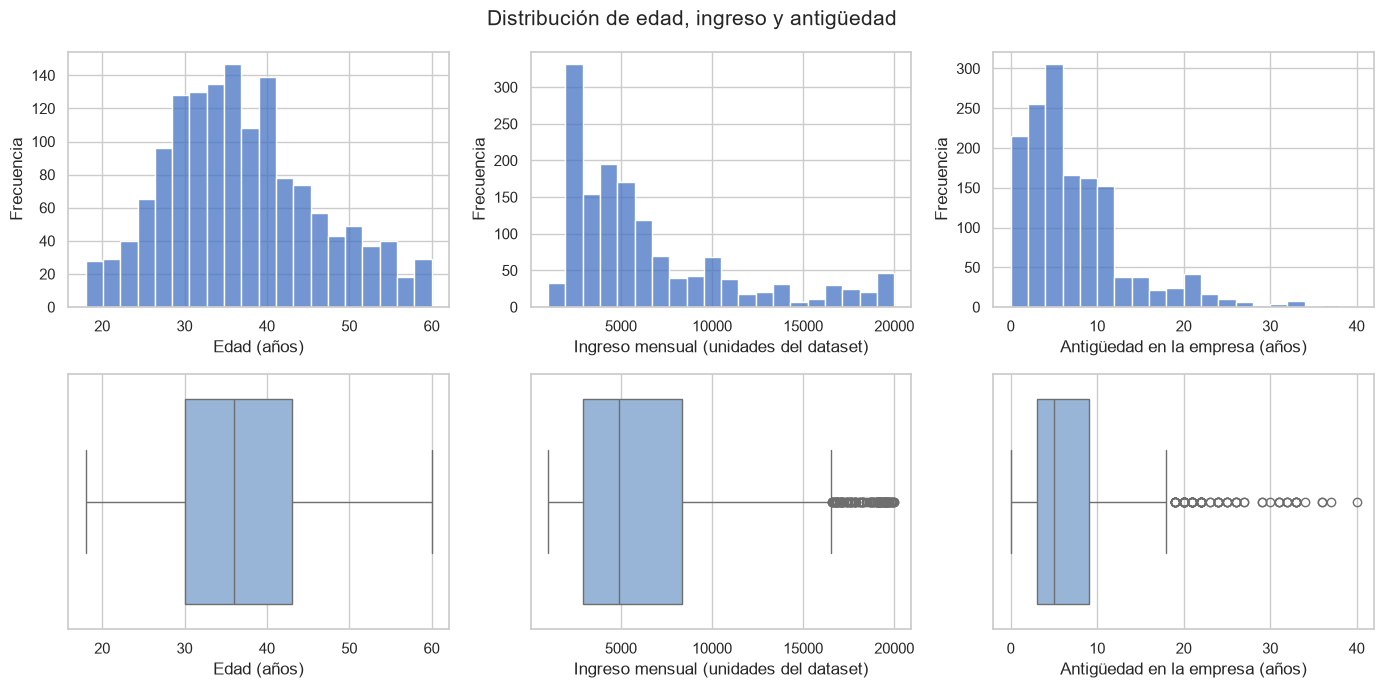

In [11]:
variables_graficos = {
    "Age": "Edad (años)",
    "MonthlyIncome": "Ingreso mensual (unidades del dataset)",
    "YearsAtCompany": "Antigüedad en la empresa (años)"
}

fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for columna, (variable, etiqueta) in enumerate(variables_graficos.items()):
    sns.histplot(
        data=analisis,
        x=variable,
        bins=20,
        color="#4472C4",
        ax=axes[0, columna]
    )
    axes[0, columna].set_xlabel(etiqueta)
    axes[0, columna].set_ylabel("Frecuencia")

    sns.boxplot(
        data=analisis,
        x=variable,
        color="#8DB4E2",
        ax=axes[1, columna]
    )
    axes[1, columna].set_xlabel(etiqueta)

fig.suptitle("Distribución de edad, ingreso y antigüedad", fontsize=15)
fig.tight_layout()

fig.savefig(
    carpeta_figuras / "figura_2_distribuciones.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Correlaciones entre variables cuantitativas

Se calcula la correlación de Spearman entre edad, ingreso, distancia,
antigüedad y experiencia laboral total. Se utiliza este método porque
permite explorar relaciones monótonas mediante rangos y resulta menos
sensible a valores extremos que la correlación de Pearson.

Una correlación no demuestra causalidad. Un valor cercano a cero
tampoco descarta relaciones de otro tipo.

,Age,MonthlyIncome,DistanceFromHome,YearsAtCompany,TotalWorkingYears
Age,"1,00","0,47","-0,02","0,25","0,66"
MonthlyIncome,"0,47","1,00","0,00","0,46","0,71"
DistanceFromHome,"-0,02","0,00","1,00","0,01","-0,00"
YearsAtCompany,"0,25","0,46","0,01","1,00","0,59"
TotalWorkingYears,"0,66","0,71","-0,00","0,59","1,00"


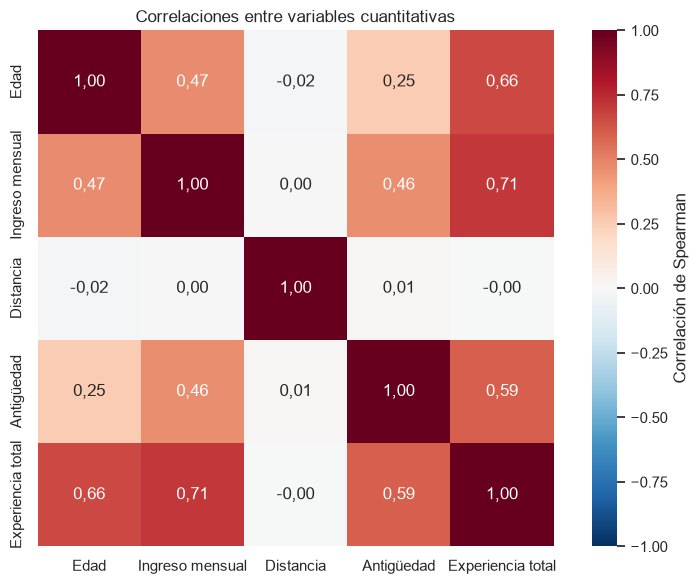

In [12]:
correlaciones = analisis[variables_numericas].corr(method="spearman")

# Tabla con dos decimales y coma decimal.
display(
    correlaciones.apply(
        lambda columna: columna.map(
            lambda valor: f"{valor:.2f}".replace(".", ",")
        )
    )
)

etiquetas = {
    "Age": "Edad",
    "MonthlyIncome": "Ingreso mensual",
    "DistanceFromHome": "Distancia",
    "YearsAtCompany": "Antigüedad",
    "TotalWorkingYears": "Experiencia total"
}

matriz_grafico = correlaciones.rename(
    index=etiquetas,
    columns=etiquetas
)

anotaciones = matriz_grafico.apply(
    lambda columna: columna.map(
        lambda valor: f"{valor:.2f}".replace(".", ",")
    )
)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    matriz_grafico,
    annot=anotaciones,
    fmt="",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=ax,
    cbar_kws={"label": "Correlación de Spearman"}
)

ax.set_title("Correlaciones entre variables cuantitativas")
fig.tight_layout()

fig.savefig(
    carpeta_figuras / "figura_3_correlaciones.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()